# Notebook 04: red neuronal convolucional (CNN)

En el notebook 02, un Random Forest con 6 características de color llegó a 0,72 de exactitud.
Acá entreno una CNN, que además del color puede aprender formas: el contorno y la textura de las manchas.

## Carga de las imágenes

Cargo las fotos de `data/tomate` con `ImageFolder`, que usa el nombre de cada carpeta como etiqueta.
A cada foto la achico de 256×256 a 64×64 (para que entrenar en CPU sea viable) y la convierto
en un tensor con valores entre 0 y 1.

Resultado: 16.011 fotos en 10 clases. Cada imagen tiene forma `[3, 64, 64]`:
PyTorch pone primero los 3 canales de color y después el alto y el ancho.

In [44]:
from torchvision import datasets, transforms 
transformacion=transforms.Compose([
    transforms.Resize((64,64)),
    transforms.ToTensor()
])
datos=datasets.ImageFolder("../data/tomate", transform=transformacion)

print (len(datos))
print(datos.classes)
print(datos[0][0].shape)

16011
['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
torch.Size([3, 64, 64])


## Separación en entrenamiento, validación y prueba

Divido las fotos en tres grupos, con una semilla fija para que la división sea siempre la misma:

- **Entrenamiento (80%, 12.809 fotos):** la red aprende de estas.
- **Validación (10%, 1.601 fotos):** las uso para decidir cuántas épocas entrenar.
- **Prueba (10%, 1.601 fotos):** se usan una sola vez, al final, para la nota definitiva.

Las fotos se entregan en lotes de 32. Las de entrenamiento se mezclan en cada pasada
para que la red no las vea siempre en el mismo orden.

In [45]:
import torch
from torch.utils.data import DataLoader, random_split  

generador= torch.Generator().manual_seed(42)
entreno, validacion, prueba = random_split(datos, [0.8, 0.1, 0.1], generator=generador)

cargador_entreno= DataLoader(entreno, batch_size=32, shuffle=True)
cargador_validacion= DataLoader(validacion, batch_size=32)
cargador_prueba=DataLoader(prueba, batch_size=32)

print(len (entreno),len (validacion),len (prueba))

imagenes, etiquetas= next (iter(cargador_entreno))
print (imagenes.shape)
print (etiquetas)


12809 1601 1601
torch.Size([32, 3, 64, 64])
tensor([6, 9, 6, 1, 0, 0, 4, 3, 8, 6, 3, 0, 6, 2, 7, 1, 1, 4, 5, 5, 5, 0, 2, 5,
        6, 1, 9, 7, 0, 6, 5, 9])


## Arquitectura de la red

La red tiene dos partes:

- **Extractor:** dos capas de convolución (16 y 32 filtros de 3×3), cada una seguida de ReLU
  y de MaxPool, que reduce la imagen a la mitad (64 → 32 → 16). Los filtros funcionan como los
  del notebook 03, pero sus valores no los elijo yo: la red los aprende.
- **Clasificador:** aplana el resultado (32 × 16 × 16 = 8.192 números) y lo pasa a 10 neuronas,
  una por clase. La clase con el puntaje más alto es la predicción.

En total la red tiene 87.018 pesos. Al pasarle un lote de 32 fotos devuelve `[32, 10]`:
10 puntajes para cada foto.

In [46]:
from torch import nn

class RedTomate(nn.Module):
    def __init__(self):
        super().__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 10),
        )

    def forward(self, x):
        x = self.extractor(x)
        return self.clasificador(x)

red = RedTomate()
salida = red(imagenes)
print(salida.shape)

torch.Size([32, 10])


## La red antes de entrenar

Miro los 10 puntajes de una foto. Como los pesos todavía son números al azar, los puntajes
son chicos y parecidos entre sí, y la clase que elige la red no tiene relación con la real.
Sin entrenar, la red acertaría más o menos 1 de cada 10 fotos: lo mismo que adivinar.

In [47]:
print(salida[0])
print ("La red dice ", salida[0].argmax().item())
print("La clase real es:", etiquetas[0].item())

tensor([ 1.2390e-02,  9.1125e-02, -1.4063e-01,  2.9188e-02, -6.2160e-03,
        -6.3636e-02,  1.1473e-02,  7.5602e-02, -1.9623e-01, -1.6510e-04],
       grad_fn=<SelectBackward0>)
La red dice  1
La clase real es: 6


## Entrenamiento

En cada lote la red sigue cuatro pasos: predice, mide su error con la función de pérdida
(CrossEntropyLoss), calcula hacia dónde mover cada peso y los corrige con el optimizador Adam.

Entreno 20 épocas. Al final de cada una mido la exactitud en entrenamiento y en validación,
y guardo una copia de los pesos cada vez que la validación supera su mejor valor.
La prueba no se mira durante el entrenamiento.

Resultado: la mejor época fue la 20, con 0,916 en validación.

In [48]:
import copy

def evaluar(red, cargador):
    red.eval()
    aciertos = 0
    total = 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            salida = red(imagenes)
            aciertos += (salida.argmax(dim=1) == etiquetas).sum().item()
            total += len(etiquetas)
    return aciertos / total

torch.manual_seed(42)
red = RedTomate()
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(red.parameters(), lr=0.001)

EPOCAS = 20
historial = []
mejor_validacion = 0
mejores_pesos = None
mejor_epoca = 0

for epoca in range(EPOCAS):
    red.train()
    for imagenes, etiquetas in cargador_entreno:
        salida = red(imagenes)
        perdida = criterio(salida, etiquetas)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()

    exactitud_entreno = evaluar(red, cargador_entreno)
    exactitud_validacion = evaluar(red, cargador_validacion)
    historial.append({"epoca": epoca + 1,
                      "entreno": exactitud_entreno,
                      "validacion": exactitud_validacion})
    print(f"Época {epoca + 1}: entreno {exactitud_entreno:.3f}, validación {exactitud_validacion:.3f}")

    if exactitud_validacion > mejor_validacion:
        mejor_validacion = exactitud_validacion
        mejores_pesos = copy.deepcopy(red.state_dict())
        mejor_epoca = epoca + 1

print("Mejor época:", mejor_epoca, "con validación", mejor_validacion)

Época 1: entreno 0.778, validación 0.746
Época 2: entreno 0.865, validación 0.828
Época 3: entreno 0.884, validación 0.851
Época 4: entreno 0.921, validación 0.881
Época 5: entreno 0.912, validación 0.870
Época 6: entreno 0.929, validación 0.866
Época 7: entreno 0.927, validación 0.870
Época 8: entreno 0.946, validación 0.889
Época 9: entreno 0.926, validación 0.870
Época 10: entreno 0.956, validación 0.901
Época 11: entreno 0.954, validación 0.886
Época 12: entreno 0.958, validación 0.884
Época 13: entreno 0.976, validación 0.906
Época 14: entreno 0.970, validación 0.899
Época 15: entreno 0.979, validación 0.909
Época 16: entreno 0.980, validación 0.913
Época 17: entreno 0.968, validación 0.888
Época 18: entreno 0.992, validación 0.913
Época 19: entreno 0.986, validación 0.898
Época 20: entreno 0.992, validación 0.916
Mejor época: 20 con validación 0.9156777014366021


## Curvas de aprendizaje

- **Hasta la época 4** las dos curvas suben juntas: la red aprende cosas que le sirven para fotos nuevas.
- **Desde la época 13** la validación queda estable entre 0,89 y 0,92, mientras el entrenamiento
  sigue subiendo hasta 0,99.
- **La distancia entre las curvas crece** (de 0,03 en la época 1 a 0,08 en la 20): es la señal
  de sobreajuste. La red empieza a memorizar las fotos de entrenamiento, por eso no conviene
  entrenar más épocas.

Los altibajos de una época a otra (por ejemplo, la caída en la 17) son normales:
importa la tendencia, no un valor suelto.

<Axes: title={'center': 'Exactitud por epoca'}, xlabel='epoca', ylabel='exactitud'>

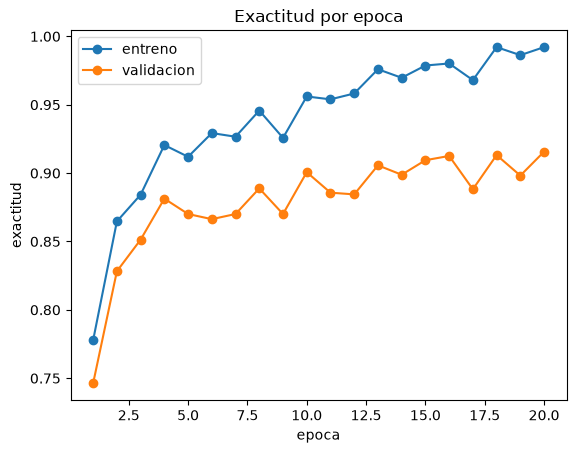

In [49]:
import  pandas as pd
curvas= pd.DataFrame(historial)
curvas.plot(x="epoca", y=["entreno","validacion"], marker="o", title= "Exactitud por epoca", ylabel="exactitud")

## Evaluación final con la prueba

Cargo los pesos de la mejor época y evalúo, por única vez, con las 1.601 fotos de prueba.

Resultado: **0,910 de exactitud**, contra 0,72 del Random Forest. Es casi igual a la de validación
(0,916), lo que indica que la red se sostiene con fotos que nunca vio.

In [55]:
red.load_state_dict(mejores_pesos)
print("Exactitud en prueba:", evaluar(red, cargador_prueba))

Exactitud en prueba: 0.910056214865709


## Resultados por clase

| Clase | Recall Random Forest | Recall CNN |
|---|---|---|
| Tizón temprano | 0,34 | 0,78 |
| Virus del mosaico | 0,53 | 0,97 |
| Hoja sana | 0,89 | 0,89 |

- **El tizón temprano mejoró más que ninguna otra clase.** Por color se confundía con otras
  enfermedades; la CNN distingue la forma de las manchas.
- **El virus del mosaico llegó a 0,97**, pero sobre solo 39 fotos de prueba, así que el número
  es poco estable.
- **La precisión de "hoja sana" es 0,99:** cuando la red dice que una hoja está sana, casi siempre
  acierta. Es la métrica más importante, porque una hoja enferma que pasa por sana no recibe tratamiento.

In [51]:
from sklearn.metrics import accuracy_score, classification_report

red.eval()
reales = []
predichas = []

with torch.no_grad():
    for imagenes, etiquetas in cargador_prueba:
        salida = red(imagenes)
        predichas.extend(salida.argmax(dim=1).tolist())
        reales.extend(etiquetas.tolist())

print("Exactitud en prueba:", accuracy_score(reales, predichas))
print(classification_report(reales, predichas, target_names=datos.classes))

Exactitud en prueba: 0.910056214865709
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.98      0.92      0.95       237
                        Tomato_Early_blight       0.76      0.78      0.77        91
                         Tomato_Late_blight       0.85      0.86      0.86       194
                           Tomato_Leaf_Mold       0.92      0.83      0.87        92
                  Tomato_Septoria_leaf_spot       0.88      0.91      0.90       163
Tomato_Spider_mites_Two_spotted_spider_mite       0.89      0.96      0.92       156
                        Tomato__Target_Spot       0.81      0.94      0.87       138
      Tomato__Tomato_YellowLeaf__Curl_Virus       0.97      0.96      0.96       334
                Tomato__Tomato_mosaic_virus       0.93      0.97      0.95        39
                             Tomato_healthy       0.99      0.89      0.94       157

                        

## Matriz de confusión

Las filas son la clase real y las columnas lo que dijo la red.

- **Solo 2 hojas enfermas fueron clasificadas como sanas** (una de Septoria y una de Target Spot).
- **De las hojas sanas que la red dio por enfermas, 14 las confundió con Target Spot.**
  Es un error menos grave: alguien revisa la planta y no encuentra nada.
- **La confusión principal es entre los dos tizones:** 16 tardíos fueron clasificados
  como tempranos y 9 tempranos como tardíos. Son enfermedades con manchas oscuras parecidas.

Text(0, 0.5, 'Clase real')

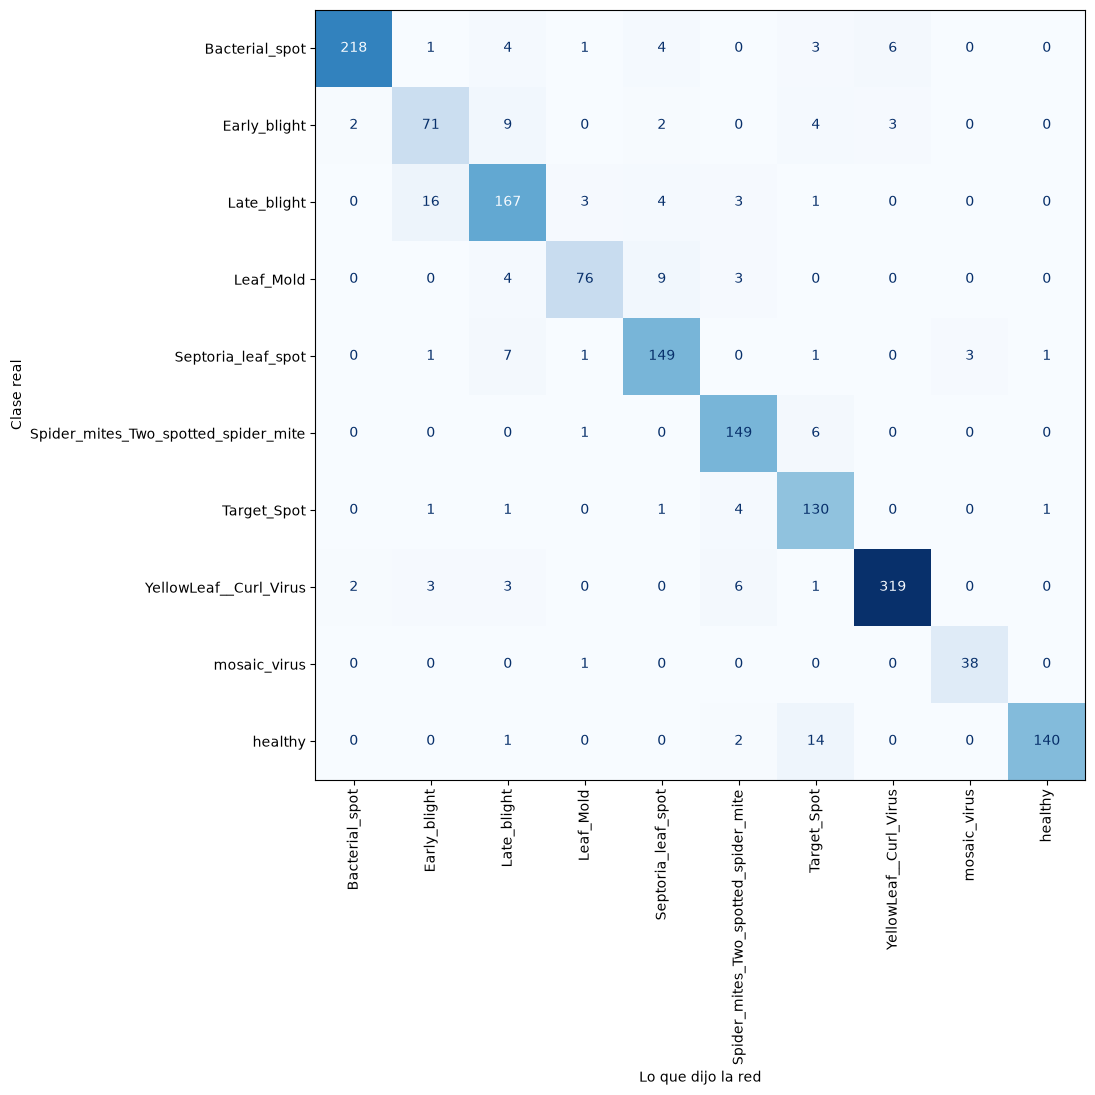

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

nombres = [c.replace("Tomato__Tomato_", "").replace("Tomato__", "").replace("Tomato_", "")
           for c in datos.classes]

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    reales, predichas,
    display_labels=nombres,
    xticks_rotation="vertical", cmap="Blues", colorbar=False, ax=ax,
)
ax.set_xlabel("Lo que dijo la red")
ax.set_ylabel("Clase real")

## Guardar el modelo

Guardo los pesos de la mejor época en `modelos/red_tomate.pt` (unos 350 KB).
Así puedo usar la red otro día sin volver a entrenarla, que en CPU lleva más de una hora.

In [53]:
from pathlib import Path

carpeta = Path("../modelos")
carpeta.mkdir(exist_ok=True)
torch.save(mejores_pesos, carpeta / "red_tomate.pt")

## Cargar el modelo guardado

Para usar la red sin entrenar: creo una red nueva y le cargo los pesos del archivo.
El mensaje `All keys matched successfully` confirma que todos los pesos se cargaron bien.

In [54]:
red = RedTomate()
red.load_state_dict(torch.load("../modelos/red_tomate.pt"))

<All keys matched successfully>

## Conclusiones

1. **La CNN superó al modelo clásico:** 0,91 contra 0,72 de exactitud en fotos que ninguno de
   los dos vio. La diferencia está en lo que miran: el Random Forest solo usaba 6 números de color,
   y la CNN aprende formas y texturas.
2. **El error más grave casi desaparece:** solo 2 de 1.444 hojas enfermas de la prueba fueron
   clasificadas como sanas.
3. **Usar validación y guardar la mejor época** permitió elegir cuánto entrenar sin contaminar
   la prueba. Las semillas fijas hacen que los resultados se puedan reproducir exactos.
4. **Pendientes:** la confusión entre tizón temprano y tardío, y confirmar el resultado del
   virus del mosaico con más fotos o con aumento de datos.